In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")

In [4]:
print(df.shape)

(100, 6)


In [5]:
#100 rows, 6 columns

In [9]:
print(df.head())

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113


In [10]:
print(df.tail())

           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


In [11]:
#the columns are named x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, y_noise_5

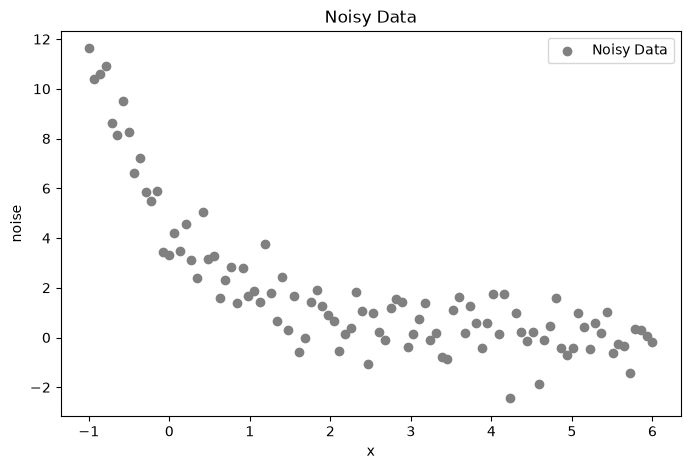

In [13]:
plt.figure(figsize = (8,5))
plt.scatter(df["x"], df["y_noise_1"], color="grey", label = "Noisy Data")
plt.xlabel("x")
plt.ylabel("noise")
plt.title("Noisy Data")
plt.legend()
plt.show()

In [16]:
x = df["x"].values
y_noise_1 = df["y_noise_1"].values

In [17]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [18]:
p0 = [1,1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)

In [19]:
A_fit, k_fit = popt

In [20]:
f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)"

'Fit: y = 4.71 * e^(-0.92 * x)'

In [21]:
residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

<function matplotlib.pyplot.show(close=None, block=None)>

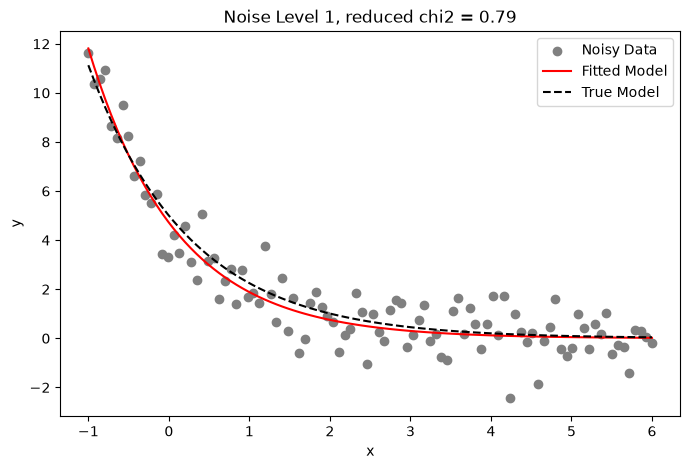

In [22]:
plt.figure(figsize=(8,5))
plt.scatter(df["x"],df["y_noise_1"], color = "grey", label = "Noisy Data")
plt.plot(x, model(x, A_fit, k_fit), color = "red", label = "Fitted Model")
plt.plot(x, model(x, 5, 0.8), color = "black", linestyle = "--", label = "True Model")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise Level 1, reduced chi2 = {chi2_reduced:.2f}")
plt.legend()
plt.show

In [25]:
 def fit_model(x,y):
     popt, pcov = curve_fit(model, x, y, p0=[1,1])
     residuals = y - model(x, *popt)
     chi2 = np.sum(residuals**2)
     dof = len(x) - len(popt)
     chi2_reduced = chi2 / dof
     return popt, chi2_reduced

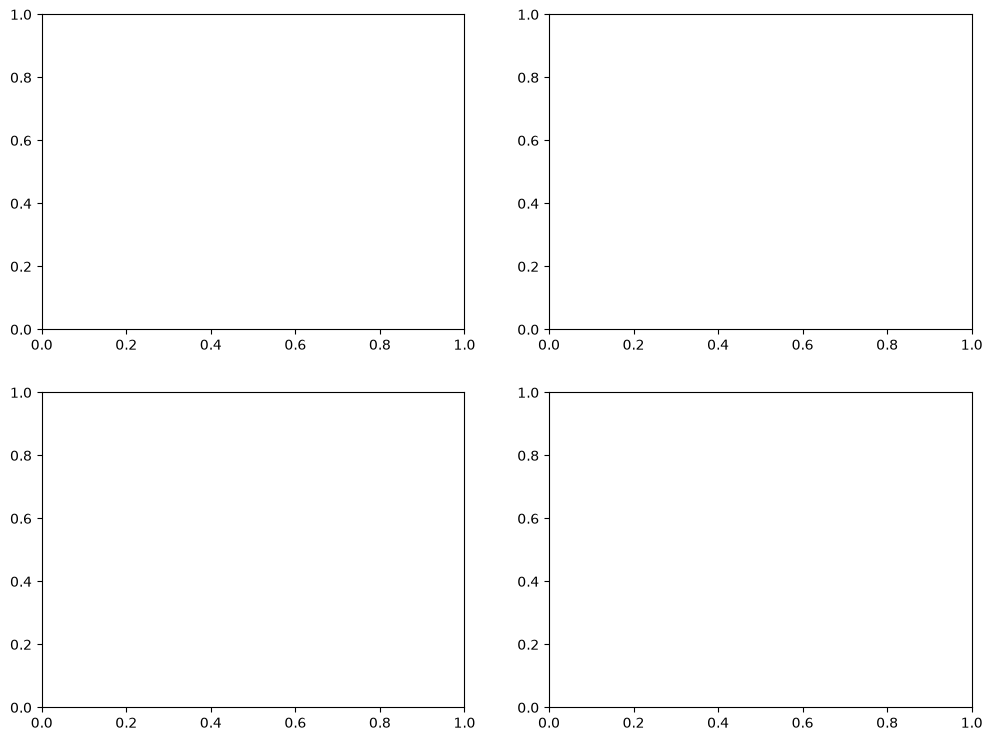

In [33]:
fig, axes = plt.subplots(2,2,figsize=(12,9))
axes = axes.flatten()

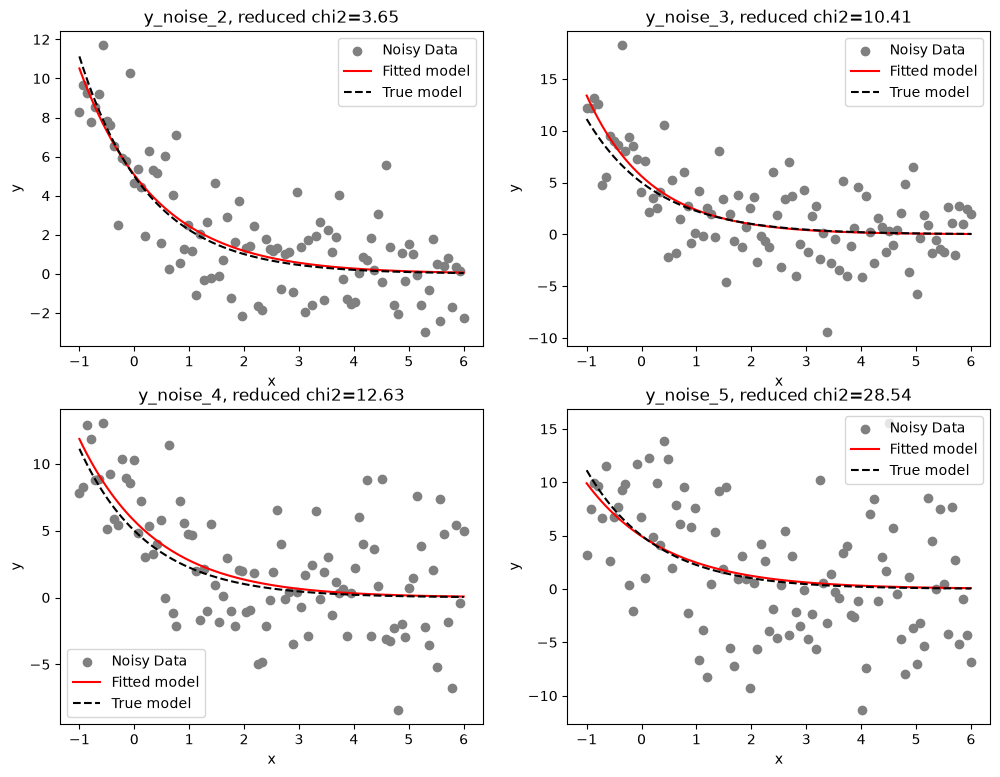

In [40]:
fig, axes = plt.subplots(2,2, figsize=(12,9))
axes = axes.flatten()
for i, ax in enumerate(axes):
    noise_level = i + 2
    y=df[f"y_noise_{noise_level}"].values
    popt, chi2_reduced = fit_model(x,y)
    A_fit, k_fit = popt
    ax.scatter(x,y, color="grey", label="Noisy Data")
    ax.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted model")
    ax.plot(x,model(x,5,0.8), color="black", linestyle = "--", label = "True model")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"y_noise_{noise_level}, reduced chi2={chi2_reduced:.2f}")
    ax.legend()
plt.show()

In [41]:
#as noise goes up, the fitted model moves fither away from the real model. reduced chi2 increases as noise does, this is because chi2 is the sum of squared residuals so the more space between residuals means a larger chi2. 

In [47]:
results = []
for noise_level in range(1, 6):
    y = df[f"y_noise_{noise_level}"].values
    popt,pcov = curve_fit(model, x, y, p0=[1,1])
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    results.append([noise_level, A_fit, k_fit, chi2_reduced])
resultsdf = pd.DataFrame(results, columns = ["Noise Level", "A_fit", "k_fit", "chi2_reduced"])
print(resultsdf)

   Noise Level     A_fit     k_fit  chi2_reduced
0            1  4.714814  0.918308      0.790673
1            2  5.063889  0.730396      3.649382
2            3  5.609396  0.870372     10.410207
3            4  5.738727  0.725965     12.626832
4            5  4.943458  0.695012     28.538124


In [49]:
resultsdf.to_csv("noisy_parameters.csv", index = "False")